# Elliptic Bitcoin Dataset: Baseline Models

Contributor: Shelly Muruganantham

This notebook uses the Elliptic Bitcoin transaction dataset to predict whether a transaction is licit or illicit.

We will first build a majority class baseline as a benchmark. We will then preprocess the transaction features and train a logistic regression model using TensorFlow. Finally, we will compare the models using accuracy, log loss, precision, and recall.

In [1]:
%pip install -q kagglehub

In [41]:
import kagglehub
from pathlib import Path
import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

path = kagglehub.dataset_download("ellipticco/elliptic-data-set")

DATA_DIR = Path(path) / "elliptic_bitcoin_dataset"

FEATURES_PATH = DATA_DIR / "elliptic_txs_features.csv"
CLASSES_PATH = DATA_DIR / "elliptic_txs_classes.csv"
EDGES_PATH = DATA_DIR / "elliptic_txs_edgelist.csv"

Using Colab cache for faster access to the 'elliptic-data-set' dataset.


# Load and Prepare the Dataset

The data is being loaded directly from the original CSV files so this notebook can run independently of other notebooks. The transaction features and labels are merged, and transactions with unknown labels are dropped. The labeled data is split into training, validation, and test sets based on time.

In [4]:
#transaction features
feature_columns = (["txId", "time_step"] + [f"feature_{i}" for i in range(1, 166)])

features = pd.read_csv(FEATURES_PATH, header=None, names=feature_columns)

#transaction labels and edges
classes = pd.read_csv(CLASSES_PATH)
edges = pd.read_csv(EDGES_PATH)

print("Features:", features.shape)
print("Classes:", classes.shape)
print("Edges:", edges.shape)

Features: (203769, 167)
Classes: (203769, 2)
Edges: (234355, 2)


# Define Outcome and Features

Features (X): The 165 numerical transaction features used to predict the transaction class.

Outcome (Y): The transaction label, where 0 represents a licit transaction and 1 represents an illicit transaction.

In [14]:
#map labels to binary values
classes["target"] = classes["class"].map({
    "1": 1,  # Illicit
    "2": 0   # Licit
})

#join features with labels
data = features.merge(
    classes[["txId", "target"]],
    on="txId",
    how="left",
    validate="one_to_one"
)

#remove transactions with unknown labels
labeled_data = data.dropna(subset=["target"]).copy()
labeled_data["target"] = labeled_data["target"].astype(int)

#same time based split used
train_data = labeled_data[labeled_data["time_step"].between(1, 34)]
val_data = labeled_data[labeled_data["time_step"].between(35, 41)]
test_data = labeled_data[labeled_data["time_step"].between(42, 49)]

#165 transaction features
feature_cols = [f"feature_{i}" for i in range(1, 166)]

X_train = train_data[feature_cols].copy()
Y_train = train_data["target"].copy()

X_val = val_data[feature_cols].copy()
Y_val = val_data["target"].copy()

X_test = test_data[feature_cols].copy()
Y_test = test_data["target"].copy()

print("Training set:", X_train.shape, Y_train.shape)
print("Validation set:", X_val.shape, Y_val.shape)
print("Test set:", X_test.shape, Y_test.shape)

print("\nTraining labels:")
print(Y_train.value_counts())


Training set: (29894, 165) (29894,)
Validation set: (7829, 165) (7829,)
Test set: (8841, 165) (8841,)

Training labels:
target
0    26432
1     3462
Name: count, dtype: int64


1. We will be using the 165 transaction features as inputs to predict the transaction label.

2. The data is split by time to mimic training on historic data and the future data the model will be predicting.

3. The test set will be for our final model after we implement our improvements.

4. The training data contains 26,432 licit transactions and 3,462 illicit transactions which means the classes are imbalanced. This is important to note because our model can reach a high accuracy by simply predicting the majority class without properly identifying the illicit transactions.

#Majority Class Classifier

A simple classification baseline predicts the most common class in the training dataset for every example and use it as the prediction for all inputs.

In [44]:
#number of examples in each class
class_counts = np.bincount(Y_train)
print(f"Licit transactions (Class 0): {class_counts[0]:,}")
print(f"Illicit transactions (Class 1): {class_counts[1]:,}")
print(f"Total labeled transactions: {len(Y_train):,}")

#majority class
majority_class = class_counts.argmax()
majority_name = "Licit" if majority_class == 0 else "Illicit"

#predict the majority class for every training example
train_baseline_preds = np.full(len(Y_train), majority_class)
val_baseline_preds = np.full(len(Y_val), majority_class)

print(f"Majority class: {majority_class} ({majority_name})")

#calculate training accuracy
train_baseline_accuracy = np.mean(train_baseline_preds == Y_train)
val_baseline_accuracy = np.mean(val_baseline_preds == Y_val)

print("Baseline Training Accuracy:", train_baseline_accuracy)
print("Baseline Validation Accuracy:", val_baseline_accuracy)

Licit transactions (Class 0): 26,432
Illicit transactions (Class 1): 3,462
Total labeled transactions: 29,894
Majority class: 0 (Licit)
Baseline Training Accuracy: 0.8841908075199036
Baseline Validation Accuracy: 0.9137820922212287


In [46]:
def ce_loss(preds, y):
    #true labels to one hot encoded form
    Y_dense = np.eye(2)[np.asarray(y, dtype=int)]
    #cross-entropy for each example
    cross_entropy_values = -np.sum(Y_dense * np.log(preds), axis=1)
    #return average cross-entropy
    return np.mean(cross_entropy_values)

#class probabilities from the training data
class_probabilities = class_counts / len(Y_train)

print(f"Probability Licit: {class_probabilities[0]:}")
print(f"Probability Illicit: {class_probabilities[1]:}")

train_preds = np.tile(class_probabilities, (len(Y_train), 1))
val_preds = np.tile(class_probabilities, (len(Y_val), 1))

#log loss
train_baseline_loss = ce_loss(train_preds, Y_train)
val_baseline_loss = ce_loss(val_preds, Y_val)

print("Baseline Training Log Loss:", train_baseline_loss)
print("Baseline Validation Log Loss:", val_baseline_loss)


Probability Licit: 0.8841908075199036
Probability Illicit: 0.11580919248009634
Baseline Training Log Loss: 0.3584910911650737
Baseline Validation Log Loss: 0.29834003036361334


The majority class is licit about 88% of the training set. The baseline predicts every transaction as licit, with a 88.42% training accuracy and 91.38% validation accuracy. The validation set has a higher proportion of licit transactions which is why it has a higher accuracy. Hence, accuracy alone may not be enough to evaluate the model.

# Feature Preprocessing and Standardization

Look at the quantiles of the training features to understand their distributions.

Standardize the training, validation, and test features using the mean and standard deviation calculated from the training set.

In [11]:
#quantiles for each feature in the training set
quantiles = np.quantile(X_train, [0.25, 0.5, 0.75, 0.95], axis=0)

#(4, 165) four quantiles for each of the 165 features
print("Quantile array shape:", quantiles.shape)

print("Quantiles for the first five features:")
print(quantiles[:, :5])

Quantile array shape: (4, 165)
Quantiles for the first five features:
[[-0.17260421 -0.18256828 -1.2013688  -0.1219696  -0.04387455]
 [-0.17045938 -0.15878252 -0.64637613 -0.04693209 -0.04387455]
 [-0.14788878 -0.10466728  1.0186019   0.02810542 -0.04387455]
 [ 0.25063709  0.15364122  1.0186019   0.7784805   0.0752256 ]]


In [15]:
#mean and standard deviation for each feature
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)

#so we don't divide by zero for any constant features
X_std[X_std == 0] = 1

#standardize the training, validation, and test sets
X_train_std = ((X_train - X_mean) / X_std)
X_val_std = ((X_val - X_mean) / X_std)
X_test_std = ((X_test - X_mean) / X_std)

print("X_train_std shape:", X_train_std.shape)
print("X_val_std shape:", X_val_std.shape)
print("X_test_std shape:", X_test_std.shape)

X_train_std shape: (29894, 165)
X_val_std shape: (7829, 165)
X_test_std shape: (8841, 165)


# Logistic Regression Model

We will use binary logistic regression with TensorFlow. The sigmoid activation function predicts the probability that a transaction is illicit. Stochastic gradient descent (SGD) updates the model's weights, and binary cross-entropy measures the prediction error.

In [17]:
def build_model(num_features, learning_rate):
  """Build a binary logistic regression model."""
  tf.keras.backend.clear_session()
  tf.random.set_seed(0)
  model = tf.keras.Sequential()
  model.add(tf.keras.layers.Dense(
      units=1,        # output dim
      input_shape=(num_features,),  # input dim
      use_bias=True,               # use a bias (intercept) param
      activation= 'sigmoid'
  ))
  optimizer = tf.keras.optimizers.SGD(learning_rate = learning_rate)
  model.compile(optimizer = optimizer, loss = 'binary_crossentropy', metrics = ['accuracy'])

  return model

In [54]:
tf.random.set_seed(0)

model_tf = build_model(num_features=X_train_std.shape[1], learning_rate=0.005)

history = model_tf.fit(X_train_std, Y_train, epochs=10, batch_size=32, validation_data=(X_val_std, Y_val))

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


935/935 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7880 - loss: 0.5015 - val_accuracy: 0.8688 - val_loss: 0.4312
Epoch 2/10
935/935 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8893 - loss: 0.3106 - val_accuracy: 0.9153 - val_loss: 0.3424
Epoch 3/10
935/935 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.8921 - loss: 0.2656 - val_accuracy: 0.9162 - val_loss: 0.3111
Epoch 4/10
935/935 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8949 - loss: 0.2446 - val_accuracy: 0.9144 - val_loss: 0.2953
Epoch 5/10
935/935 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8984 - loss: 0.2320 - val_accuracy: 0.9116 - val_loss: 0.2873
Epoch 6/10
935/935 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9024 - loss: 0.2234 - val_accuracy: 0.9091 - val_loss: 0.2823
Epoch 7/10
935/935 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9053 - loss: 0.2172 - val_accuracy: 0.9068 - val_loss: 0.2787
Epoch 8/10
935/935 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9081 - loss: 0.2124 - val_accuracy: 0.9061 - val_

I tested different learning rates, numbers of epochs, and batch sizes to see how they affected model performance. Out of the various trials, a learning rate of 0.005 and a batch size of 32 gave the best validation accuracy.

The model reached 90.36% validation accuracy and a validation loss of 0.2717 after 10 epochs. The validation accuracy was highest at epoch 3 (91.62%) and then gradually decreased even though its loss continued to improve.

I chose this configuration for now because it performed well overall and had a lower validation loss than the majority class baseline.

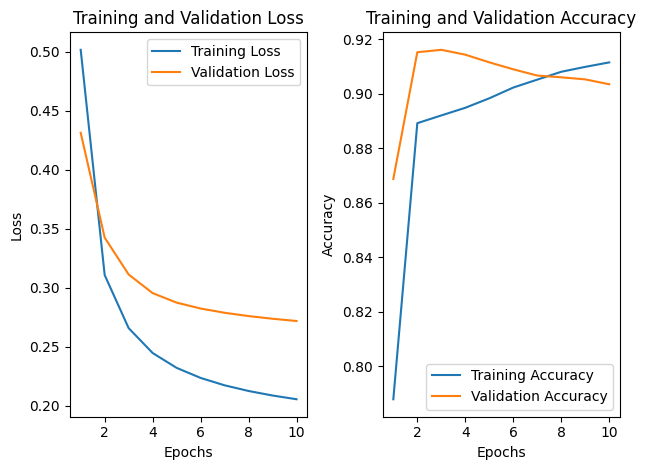

In [55]:
#plots training and validation performance
epochs = range(1, 11)

#training and validation loss
plt.subplot(1, 2, 1)
plt.plot(epochs, history.history['loss'], label='Training Loss')
plt.plot(epochs, history.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

#training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, history.history['accuracy'], label='Training Accuracy')
plt.plot(epochs, history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

The training loss decreases over the 10 epochs and the training accuracy increases meaning that the model is learning patterns from the training data. The validation loss also decreases throughout. The validation accuracy reaches about 91.6% at epoch 3 then slowly decreases to about 90% by epoch 10. Hence, the epoch with the highest validation accuracy is not the epoch with the lowest validation loss. The final training accuracy is just a bit higher than the vaidation accuracy.

# Evaluation and Generalization

In [56]:
print("Baseline Validation Accuracy:", val_baseline_accuracy)
print("Baseline Validation Loss:", val_baseline_loss)

Baseline Validation Accuracy: 0.9137820922212287
Baseline Validation Loss: 0.29834003036361334


In [58]:
#evaluate logistic regression on validation data
val_loss, val_accuracy = model_tf.evaluate(
    X_val_std, Y_val, verbose=0
)
print("Logistic Regression Validation Accuracy:", val_accuracy)
print("Logistic Regression Validation Loss:", val_loss)

Logistic Regression Validation Accuracy: 0.9035636782646179
Logistic Regression Validation Loss: 0.27168798446655273


The baseline has an accuracy of about 91% versus logistic regression which has an accuracy of 90%, meaning our baseline performs better when looking at accuracy. However, this also simply means that about 91% of our transactions are licit. However, logistic regression has a lower loss (0.2717 versus 0.2983) meaning its predicted probabilites are better aligned with the actual labels on average.

The training and validation accuracies are pretty close, but the validation accuracy starts to decrease after epoch 3 while training accuracy continues to increase. This may suggest that the model could be starting to overfit so we should keep validation performance in mind when for the number of epochs.

#Additional metrics



True Negatives (licit correctly predicted): 6533
False Positives (licit predicted as illicit): 621
False Negatives (illicit predicted as licit): 134
True Positives (illicit correctly predicted): 541


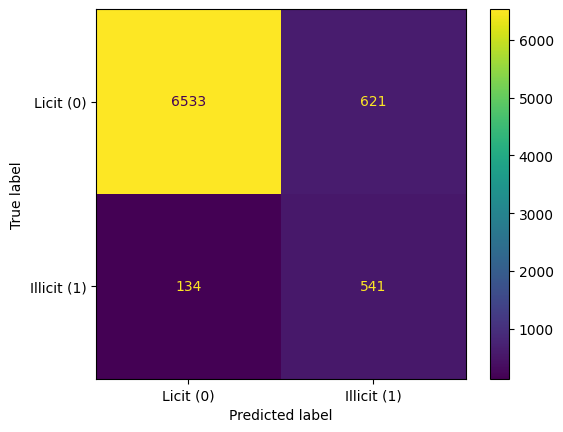

In [59]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

val_pred_prob = model_tf.predict(X_val_std, verbose=0)
val_pred = (val_pred_prob >= 0.5).astype(int)
cm = confusion_matrix(Y_val, val_pred, labels=[0, 1])

TN = cm[0, 0]
FP = cm[0, 1]
FN = cm[1, 0]
TP = cm[1, 1]

print("True Negatives (licit correctly predicted):", cm[0, 0])
print("False Positives (licit predicted as illicit):", cm[0, 1])
print("False Negatives (illicit predicted as licit):", cm[1, 0])
print("True Positives (illicit correctly predicted):", cm[1, 1])

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Licit (0)", "Illicit (1)"])
disp.plot()
plt.show()

The logistic regression model correctly identifies 541 illicit transactions but misses 134. It also incorrectly flags 621 licit transactions as illicit. Unlike the baseline, which misses all illicit transactions, logistic regression can identify illicit activity, however it does give us some false alarms.

In [60]:
precision = TP / (TP + FP)
recall = TP / (TP + FN)

print("Illicit Precision:", precision)
print("Illicit Recall:", recall)

Illicit Precision: 0.4655765920826162
Illicit Recall: 0.8014814814814815


The model correctly identifies about 47% of the transactions it predicts are illicit. The other 53% are licit transactions that the model incorrectly flags as illicit. Illicit recall is approximately 80.1%, meaning that the model identifies about 80% of all actual illicit transactions in the validation set. The model catches most illicit transactions but produces a considerable number of false positives.